# 09 · Model comparison (handbook Table 3.7) and predictions for the scoring file
Pick the model on validation results; the test scores below are reported once per final model.

In [10]:
import sys
from pathlib import Path

# find the project root (the folder that contains src/dsc_utils.py) and import the shared helpers
root = Path.cwd()
while not (root / "src" / "dsc_utils.py").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dsc_utils import *

In [12]:
results = pd.read_csv(RESULTS_FILE).drop_duplicates("model", keep="last")
results.sort_values("macro_F1", ascending=False).round(4)

,model,accuracy,macro_F1,ordinal_MAE,within_one,EFG_recall,AUC_ovr
4,HistGradientBoosting,0.6692,0.6791,0.4708,0.9009,0.8110,0.9448
0,Decision Tree,0.6186,0.6290,0.5483,0.8831,0.7818,0.9225
5,"SVM (RBF, 15k sample)",0.5122,0.4970,0.7120,0.8422,0.7207,NaN
2,kNN (SVD-50),0.5162,0.4884,0.7516,0.8154,0.7473,0.8782
1,Logistic Regression,0.5017,0.4849,0.7503,0.8240,0.7321,0.8745
3,SVM (linear),0.4685,0.4360,0.8351,0.7942,0.7402,NaN


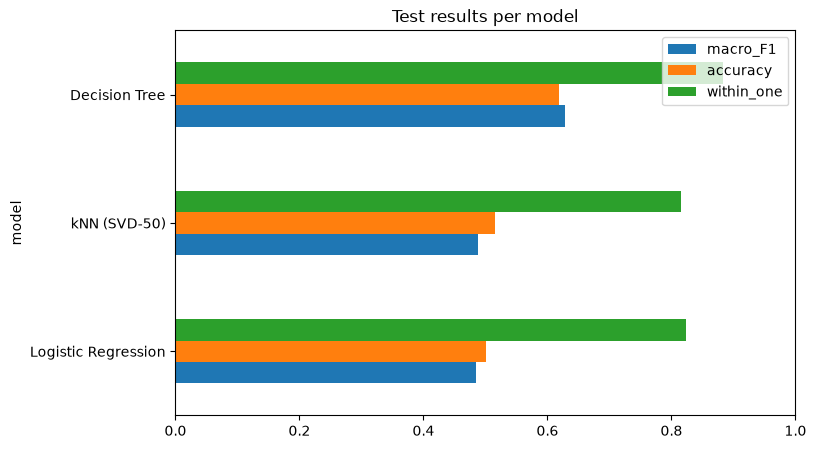

In [3]:
r = results.set_index("model").sort_values("macro_F1")
r[["macro_F1", "accuracy", "within_one"]].plot(kind="barh", figsize=(8, 5))
plt.title("Test results per model"); plt.xlim(0, 1); plt.show()

## Predict the scoring file with the chosen model

In [6]:
BEST = "DT"           # file name used in save_model(): DT, LR, RF, SVM_linear, SVM_rbf, KNN or HGB

d = load_prepared()
best = load_model(BEST)
X_score = d["score_data"] if BEST == "HGB" else d["x_score"]

# Optional: refit the chosen model on train + validation before predicting (same hyperparameters)

submission = pd.DataFrame({"finc_id": d["score_ids"], "EPC label": best.predict(X_score)})
print(submission.shape)
print(pd.DataFrame({"training": pd.Series(d["y_train"]).value_counts(normalize=True),
                    "predicted": submission["EPC label"].value_counts(normalize=True)}).reindex(ORDER).round(3))

(76906, 2)
    training  predicted
A+     0.008      0.006
A      0.070      0.068
B      0.154      0.165
C      0.198      0.227
D      0.184      0.177
E      0.131      0.113
F      0.190      0.173
G      0.066      0.070


Step 1: Find where the errors are (error analysis)

In [8]:
d = load_prepared()
name = "DT"                                                    # your best model
model = load_model(name)
te = d["data"].iloc[d["indices_test"]]
X = te if name == "HGB" else d["x_test"]
pred, y = model.predict(X), d["y_test"]

err = pd.DataFrame({"true": y, "pred": pred, "region": te["region"].values,
                    "period_only": te["builtyear_is_range"].values,
                    "building_type": te["building type"].values})
err["correct"] = err["true"] == err["pred"]
err["within_one"] = (err["true"].map(TO_I) - err["pred"].map(TO_I)).abs() <= 1

print(err.groupby("region")[["correct", "within_one"]].mean().round(3))
print(err.groupby("period_only")[["correct", "within_one"]].mean().round(3))   # 1 = only a period known
print(err.groupby("building_type")[["correct"]].agg(["mean", "size"]).round(3))
print(pd.crosstab(err["true"], err["pred"], normalize="index").reindex(index=ORDER, columns=ORDER).round(2))

          correct  within_one
region                       
Brussels    0.500       0.812
Flanders    0.676       0.902
Wallonia    0.535       0.861
             correct  within_one
period_only                     
0              0.822       0.971
1              0.581       0.867
                  correct       
                     mean   size
building_type                   
annex               0.670    115
building            0.602   5459
freeStandingHouse   0.650  11847
health              0.500      4
industrial          0.577    620
public              0.542     24
school              0.567     30
semiAttachedHouse   0.648   8396
sport               0.400      5
terracedHouse       0.564   9390
pred    A+     A     B     C     D     E     F     G
true                                                
A+    0.56  0.35  0.06  0.02  0.00  0.00  0.00  0.00
A     0.02  0.81  0.13  0.03  0.01  0.00  0.01  0.00
B     0.00  0.04  0.75  0.17  0.03  0.01  0.01  0.00
C     0.00  0.01  0.14  

Step 2: Use the region-specific scales

In [9]:
# labels that occur in each region in the TRAINING data (at least 0.1%)
tr = d["data"].iloc[d["indices_train"]]
share = pd.crosstab(tr["region"], d["y_train"], normalize="index")
allowed = share >= 0.001

proba = class_scores(model, X)
for region in allowed.index:
    rows = (te["region"].values == region)
    for label in proba.columns:
        if not allowed.loc[region, label]:
            proba.loc[rows, label] = 0
pred_adj = proba.idxmax(axis=1).to_numpy()
print("accuracy before:", round((pred == y).mean(), 4), "| after:", round((pred_adj == y).mean(), 4))

accuracy before: 0.6186 | after: 0.6187


##Print kết quả

In [ ]:
out = OUT / "predictions_group22.csv"      # check the organisers' required format first
submission.to_csv(out, index=False)
print("Saved", out)